# Gaussian Mixture Model (EM)

Model the data as coming from `k` Gaussians, each with its own **weight, mean and full covariance**. This is K-Means (`27_kmeans`) made probabilistic:

| | K-Means | Gaussian Mixture |
|---|---|---|
| Assignment | hard (one cluster) | **soft** — a probability per cluster |
| Cluster shape | round (equal spread) | **elliptical**, any orientation and size |
| Output | labels | labels + `predict_proba` + a full density model |

K-Means is the special case of equal, spherical clusters with hard assignments.

## Expectation-Maximization

Alternate until the likelihood stops improving:

- **E-step:** each point's *responsibility* for component `k` — the posterior `weight_k · N(x | mean_k, cov_k) / p(x)`.
- **M-step:** refit each component to the data, weighting every point by its responsibility: new weight = share of responsibility, new mean = weighted average, new covariance = weighted scatter.

Each iteration provably never lowers the log-likelihood (`log_likelihood_history_` makes that visible), but EM only finds a *local* optimum, so initialization matters — here k-means++ seeds plus a few Lloyd steps. Densities are computed in log-space via Cholesky factors; `reg_covar` keeps covariances invertible.

**Choosing `k`:** `bic(X)` penalizes extra parameters — fit several `k` and take the lowest BIC.

## Usage

```python
# (the class is defined in the Implementation section below)

gmm = GaussianMixture(n_components=3).fit(X)
gmm.means_, gmm.covariances_, gmm.weights_
gmm.predict_proba(X)     # soft assignments
gmm.bic(X)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _log_gaussian(X, mean, cov):
    """log N(x | mean, cov) for every row of X."""
    d = X.shape[1]
    L = np.linalg.cholesky(cov)
    z = np.linalg.solve(L, (X - mean).T)  # whitened differences
    log_det = 2.0 * np.log(np.diag(L)).sum()
    return -0.5 * (d * np.log(2 * np.pi) + log_det + (z**2).sum(axis=0))


def _logsumexp(a):
    m = a.max(axis=1, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=1, keepdims=True))).ravel()


class GaussianMixture:
    """Soft clustering: the data is modelled as k Gaussians, each with its own weight, mean and full
    covariance. Fitted by Expectation-Maximization:

    E-step: for every point compute the RESPONSIBILITY of each component (its posterior probability).
    M-step: re-estimate every component's weight, mean and covariance from the responsibility-weighted data.

    Each iteration is guaranteed not to decrease the log-likelihood (log_likelihood_history_ shows it).
    Unlike K-Means, points belong to clusters with a probability, and clusters can be elliptical.

    reg_covar is added to every covariance diagonal so a component can't collapse onto a point.
    ponytail: single k-means style initialization, not several restarts; EM only finds a local optimum."""

    def __init__(self, n_components=3, max_iter=200, tol=1e-8, reg_covar=1e-6, random_state=0):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol
        self.reg_covar = reg_covar
        self.random_state = random_state

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)
        self._m_step(X, self._initial_responsibilities(X, rng))

        self.log_likelihood_history_ = []
        previous = -np.inf
        for _ in range(self.max_iter):
            log_norm, resp = self._e_step(X)
            ll = log_norm.mean()
            self.log_likelihood_history_.append(ll)
            self._m_step(X, resp)
            if abs(ll - previous) < self.tol:
                break
            previous = ll
        self.labels_ = self.predict(X)
        return self

    def _initial_responsibilities(self, X, rng):
        # k-means++ seeds, a few Lloyd steps, then hard assignments as the starting responsibilities
        n, k = len(X), self.n_components
        centers = [X[rng.integers(n)]]
        for _ in range(1, k):
            d2 = np.min([((X - c) ** 2).sum(axis=1) for c in centers], axis=0)
            centers.append(X[rng.choice(n, p=d2 / d2.sum())])
        centers = np.array(centers)
        for _ in range(10):
            labels = ((X[:, None] - centers[None]) ** 2).sum(-1).argmin(axis=1)
            centers = np.array([X[labels == c].mean(axis=0) if (labels == c).any() else centers[c] for c in range(k)])
        return np.eye(k)[((X[:, None] - centers[None]) ** 2).sum(-1).argmin(axis=1)]

    def _e_step(self, X):
        log_prob = np.column_stack([
            np.log(w) + _log_gaussian(X, m, c)
            for w, m, c in zip(self.weights_, self.means_, self.covariances_)
        ])
        log_norm = _logsumexp(log_prob)  # log p(x) for each point
        return log_norm, np.exp(log_prob - log_norm[:, None])

    def _m_step(self, X, resp):
        n, d = X.shape
        nk = resp.sum(axis=0) + 1e-12  # effective number of points in each component
        self.weights_ = nk / n
        self.means_ = (resp.T @ X) / nk[:, None]
        self.covariances_ = np.array([
            ((resp[:, k, None] * (X - self.means_[k])).T @ (X - self.means_[k])) / nk[k]
            + self.reg_covar * np.eye(d)
            for k in range(self.n_components)
        ])

    def predict_proba(self, X):
        return self._e_step(np.asarray(X, dtype=float))[1]

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def score(self, X):
        """Average log-likelihood per sample."""
        return self._e_step(np.asarray(X, dtype=float))[0].mean()

    def bic(self, X):
        """Bayesian Information Criterion: lower is better; penalizes extra components."""
        X = np.asarray(X, dtype=float)
        n, d = X.shape
        k = self.n_components
        n_params = k * d + k * d * (d + 1) // 2 + (k - 1)
        return -2.0 * self.score(X) * n + n_params * np.log(n)

## See it work

### 1. EM, step by step

A Gaussian mixture models the data as a blend of `k` Gaussians. **EM** alternates:
- **E-step:** for each point, the *responsibility* of each Gaussian (probability it generated that point).
- **M-step:** re-estimate each Gaussian's weight, mean and covariance from the responsibility-weighted points.

The ellipses are the 2σ contours of each component after `n` iterations; they start badly and lock onto the data.

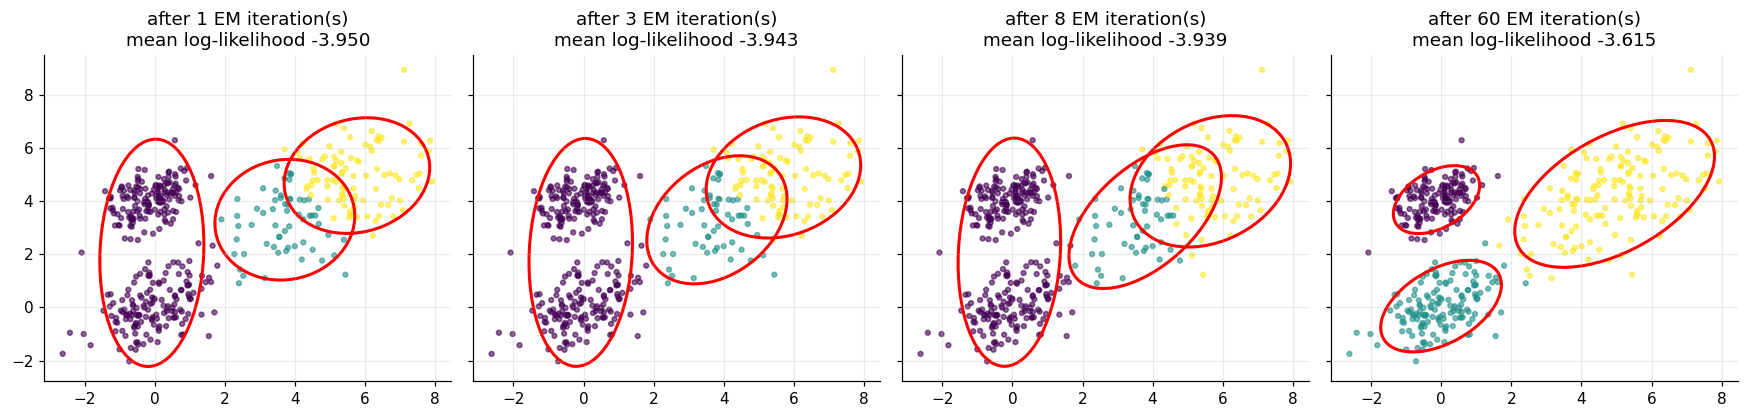

In [3]:
from matplotlib.patches import Ellipse

def draw_gaussian(ax, mean, cov, color="k", n_std=2.0, **kw):
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    ax.add_patch(Ellipse(mean, 2 * n_std * np.sqrt(vals[1]), 2 * n_std * np.sqrt(vals[0]), angle=angle, fill=False, color=color, lw=2, **kw))

from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=450, centers=[[0, 0], [5, 3], [0, 5]], cluster_std=[0.9, 1.4, 0.7], random_state=3)
X = X @ np.array([[1.0, 0.4], [0.0, 0.8]])                      # stretch it so the Gaussians are tilted ellipses
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharex=True, sharey=True)
for ax, it in zip(axes, [1, 3, 8, 60]):
    g = GaussianMixture(n_components=3, max_iter=it, tol=0.0, random_state=1).fit(X)
    ax.scatter(*X.T, c=g.predict(X), cmap="viridis", s=10, alpha=0.6)
    for mu, cov, c in zip(g.means_, g.covariances_, ["C0", "C1", "C2"]): draw_gaussian(ax, mu, cov, color="r")
    ax.set_title(f"after {it} EM iteration(s)\nmean log-likelihood {g.score(X):.3f}")
plt.tight_layout(); plt.show()

### 2. Soft assignments

Unlike K-Means, each point gets a **probability** for each component. Points between two clusters are genuinely uncertain, and that uncertainty is information. Dot size below is how *uncertain* (1 − max probability) the model is about that point.

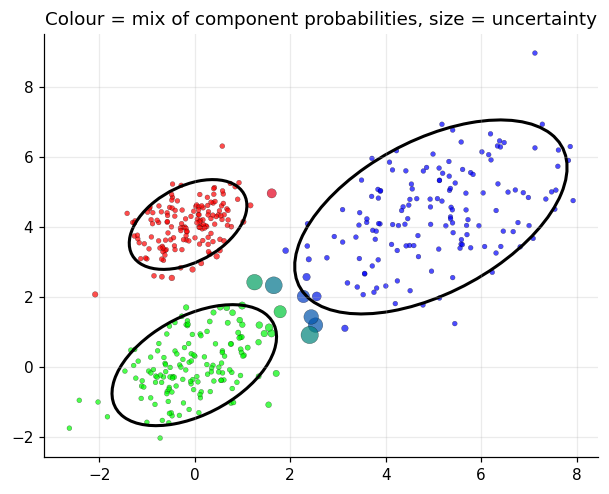

In [4]:
g = GaussianMixture(n_components=3, random_state=1).fit(X)
P = g.predict_proba(X)
uncertainty = 1 - P.max(axis=1)
plt.figure(figsize=(6.5, 5))
plt.scatter(*X.T, c=P, s=10 + 250 * uncertainty, alpha=0.7, edgecolor="k", linewidth=0.2)
for mu, cov in zip(g.means_, g.covariances_): draw_gaussian(plt.gca(), mu, cov, color="k")
plt.title("Colour = mix of component probabilities, size = uncertainty"); plt.show()

### 3. Choosing `k`: BIC

More components always raise the likelihood, so we need a penalty. **BIC** = `−2·log-likelihood + (#parameters)·log n`; lower is better. It bottoms out at the true `k = 3`. The right panel shows the log-likelihood rising monotonically during EM, as the algorithm guarantees.

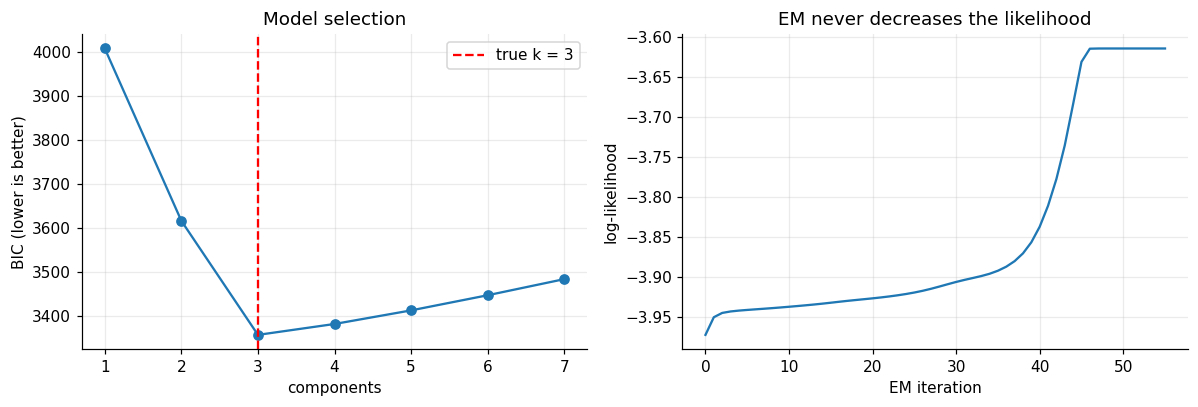

In [5]:
ks = range(1, 8)
bics = [GaussianMixture(n_components=k, random_state=1).fit(X).bic(X) for k in ks]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.plot(list(ks), bics, "o-"); a.axvline(3, color="r", ls="--", label="true k = 3"); a.set(xlabel="components", ylabel="BIC (lower is better)", title="Model selection"); a.legend()
b.plot(g.log_likelihood_history_); b.set(xlabel="EM iteration", ylabel="log-likelihood", title="EM never decreases the likelihood")
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture as SklearnGMM

X, truth = make_blobs(n_samples=600, centers=3, cluster_std=[1.0, 2.0, 0.6], random_state=3)

ours = GaussianMixture(n_components=3, tol=1e-10, max_iter=1000).fit(X)
theirs = SklearnGMM(n_components=3, covariance_type="full", tol=1e-10, max_iter=1000, reg_covar=1e-6, random_state=0).fit(X)

print("avg log-likelihood: ours=%.6f sklearn=%.6f" % (ours.score(X), theirs.score(X)))
print("agreement with sklearn labels (ARI) = %.4f" % adjusted_rand_score(ours.predict(X), theirs.predict(X)))
print("agreement with true blobs (ARI)     = %.4f" % adjusted_rand_score(ours.predict(X), truth))
print("EM iterations: %d, log-likelihood %.3f -> %.3f"
      % (len(ours.log_likelihood_history_), ours.log_likelihood_history_[0], ours.log_likelihood_history_[-1]))
assert abs(ours.score(X) - theirs.score(X)) < 1e-4
assert np.allclose(np.sort(ours.means_, axis=0), np.sort(theirs.means_, axis=0), atol=1e-3)
assert adjusted_rand_score(ours.predict(X), theirs.predict(X)) > 0.99

avg log-likelihood: ours=-4.039581 sklearn=-4.039581
agreement with sklearn labels (ARI) = 1.0000
agreement with true blobs (ARI)     = 0.9752
EM iterations: 18, log-likelihood -4.047 -> -4.040


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _mixture(n=900, seed=0):
    rng = np.random.default_rng(seed)
    sizes = [int(n * 0.2), int(n * 0.3), n - int(n * 0.2) - int(n * 0.3)]
    covs = [[[1.0, 0.0], [0.0, 1.0]], [[2.0, 1.2], [1.2, 1.0]], [[0.5, 0.0], [0.0, 2.0]]]
    means = [[-6, 0], [0, 6], [6, -2]]
    X = np.vstack([rng.multivariate_normal(m, c, s) for m, c, s in zip(means, covs, sizes)])
    return X, np.repeat([0, 1, 2], sizes)


def test_log_likelihood_never_decreases():
    X, _ = _mixture()
    ll = GaussianMixture(n_components=3, tol=0).fit(X).log_likelihood_history_
    assert len(ll) > 3
    assert all(b >= a - 1e-9 for a, b in zip(ll, ll[1:]))  # the defining property of EM


def test_recovers_the_true_parameters():
    X, truth = _mixture()
    model = GaussianMixture(n_components=3).fit(X)
    order = np.argsort(model.means_[:, 0])  # components sorted left to right
    assert np.allclose(model.weights_[order], [0.2, 0.3, 0.5], atol=0.04)
    assert np.allclose(model.means_[order], [[-6, 0], [0, 6], [6, -2]], atol=0.3)
    assert abs(model.covariances_[order][1][0, 1] - 1.2) < 0.3   # learned a tilted (elliptical) shape
    pred = model.predict(X)  # label ids are arbitrary, so score by purity instead of equality
    assert sum(np.bincount(pred[truth == c]).max() for c in range(3)) / len(X) > 0.95


def test_probabilities_and_bic_picks_the_right_number_of_components():
    X, _ = _mixture()
    probs = GaussianMixture(n_components=3).fit(X).predict_proba(X)
    assert np.allclose(probs.sum(axis=1), 1.0)
    bics = {k: GaussianMixture(n_components=k).fit(X).bic(X) for k in range(1, 6)}
    assert min(bics, key=bics.get) == 3

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_log_likelihood_never_decreases
PASS test_recovers_the_true_parameters


PASS test_probabilities_and_bic_picks_the_right_number_of_components

all 3 tests passed


## Takeaways

- **Use it** for clustering with elliptical clusters of different shapes and sizes, soft assignments, density estimation, and as the continuous cousin of K-Means (K-Means is GMM with equal, spherical covariances and hard assignments).
- **Pitfalls:** EM finds a local optimum (restart), a component can collapse onto one point (the `reg_covar` term keeps covariances invertible), you must choose `k` (use BIC/AIC), and it assumes the clusters are Gaussian.
- **Computation:** work in log space with log-sum-exp; the Cholesky factor gives the log-determinant and the quadratic form cheaply.
- **Interview line:** *"Mixture of Gaussians fitted by EM: E-step computes responsibilities, M-step updates weights, means and covariances; the likelihood increases every iteration."*